## Step 1: Imports and configuration

In [1]:
import os, ast, json, random, shutil, warnings
import numpy as np
import pandas as pd
import pydicom
import cv2
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

COMP = "/kaggle/input/competitions/rsna-intracranial-aneurysm-detection"
PNG_BASE = "/kaggle/input/datasets/dennisfong/rsna-2025-intracranial-aneurysm-png-224x224"
WRONG_PREFIX = "/kaggle/input/rsna-intracranial-aneurysm-detection"
RIGHT_PREFIX = COMP

OUT = "/kaggle/working"
PNG_DIR = f"{OUT}/v2_png"
IMG_SIZE = 224
BOX_SIZE = 20                                   # synthetic box edge in pixels (only point labels exist)
MODALITY_MAP = {"CTA": 0, "MRA": 1, "MRI T1post": 2, "MRI T2": 3}
SPLITS = {"70_15_15": 0.70, "80_10_10": 0.80, "85_7dot5_7dot5": 0.85}

## Step 2: Load index files and build look-up tables

In [2]:
train_df = pd.read_csv(f"{COMP}/train.csv")
series_map = pd.read_csv(f"{PNG_BASE}/series_index_mapping.csv")
localizers = pd.read_csv(f"{PNG_BASE}/train_localizers_with_relative.csv")

if "Modality" not in train_df.columns:
    lookup = series_map[["SeriesInstanceUID", "Modality"]].drop_duplicates()
    train_df = train_df.merge(lookup, on="SeriesInstanceUID", how="left")
train_df["modality_code"] = train_df["Modality"].map(MODALITY_MAP)

series_map["dicom_filename"] = series_map["dicom_filename"].str.replace(WRONG_PREFIX, RIGHT_PREFIX, regex=False)
sop_to_path = dict(zip(series_map["SOPInstanceUID"], series_map["dicom_filename"]))
sop_to_rel = dict(zip(series_map["SOPInstanceUID"], series_map["relative_index"]))
n_slices = (series_map.groupby("SeriesInstanceUID")["relative_index"].max() + 1).to_dict()
slice_lookup = {(s, i): f for s, i, f in zip(series_map["SeriesInstanceUID"],
                                              series_map["relative_index"],
                                              series_map["dicom_filename"])}

print("train_df:", train_df.shape)
print(train_df["Modality"].value_counts().to_string())
print("Positive series:", int((train_df["Aneurysm Present"] == 1).sum()),
      "| Negative series:", int((train_df["Aneurysm Present"] == 0).sum()))

train_df: (4348, 19)
Modality
CTA           1808
MRA           1252
MRI T2         983
MRI T1post     305
Positive series: 1863 | Negative series: 2485


## Step 3: One normaliser for every image (DICOM -> 224x224 PNG)

In [3]:
def n_frames(dicom_path):
    d = pydicom.dcmread(dicom_path, stop_before_pixels=True)
    n = getattr(d, "NumberOfFrames", 1)
    try:
        return int(n) if n is not None else 1
    except (TypeError, ValueError):
        return 1

def normalize_to_png(dicom_path, save_path, size=IMG_SIZE):
    """Percentile-window (1-99) to 8 bit and resize. Returns the original (height, width)."""
    arr = pydicom.dcmread(dicom_path).pixel_array.astype(np.float32)
    if arr.ndim == 3:                               # not expected: multi-frame series are excluded upstream
        arr = arr[arr.shape[0] // 2]
    h, w = arr.shape
    p1, p99 = np.percentile(arr, [1, 99])
    if p99 > p1:
        arr = (np.clip(arr, p1, p99) - p1) / (p99 - p1) * 255.0
    else:
        arr = np.zeros_like(arr)
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    Image.fromarray(arr.astype(np.uint8)).resize((size, size), Image.LANCZOS).save(save_path)
    return h, w

def rel(path):
    return os.path.relpath(path, OUT)

## Step 4: Positive images (one image per annotated slice)

In [4]:
pos_series = set(train_df.loc[train_df["Aneurysm Present"] == 1, "SeriesInstanceUID"])
loc_pos = localizers[localizers["SeriesInstanceUID"].isin(pos_series)].copy()

pos_dir = f"{PNG_DIR}/positive"
pos_rows, excluded_series, failed = [], set(), []
for sop_uid, grp in tqdm(loc_pos.groupby("SOPInstanceUID"), total=loc_pos["SOPInstanceUID"].nunique()):
    series_uid = grp["SeriesInstanceUID"].iloc[0]
    if sop_uid not in sop_to_path:
        failed.append(sop_uid)
        continue
    dpath = sop_to_path[sop_uid]
    try:
        if n_frames(dpath) > 1:
            excluded_series.add(series_uid)
            continue
        save_path = f"{pos_dir}/{sop_uid}.png"
        h, w = normalize_to_png(dpath, save_path)
    except Exception as e:
        failed.append(sop_uid)
        continue
    rel_pos = sop_to_rel[sop_uid] / max(n_slices[series_uid] - 1, 1)
    for _, r in grp.iterrows():
        c = ast.literal_eval(r["coordinates"]) if isinstance(r["coordinates"], str) else r["coordinates"]
        pos_rows.append(dict(SeriesInstanceUID=series_uid, SOPInstanceUID=sop_uid, image_path=rel(save_path),
                             location=r["location"],
                             x_center=float(np.clip(c["x"] / w, 0, 1)), y_center=float(np.clip(c["y"] / h, 0, 1)),
                             box_w=BOX_SIZE / IMG_SIZE, box_h=BOX_SIZE / IMG_SIZE, rel_pos=rel_pos))

pos_v2 = pd.DataFrame(pos_rows)
pos_v2 = pos_v2[~pos_v2["SeriesInstanceUID"].isin(excluded_series)].reset_index(drop=True)
print("Multi-frame positive series excluded:", len(excluded_series))
print("Failed slices:", len(failed))
print("Positive series:", pos_v2["SeriesInstanceUID"].nunique(),
      "| images:", pos_v2["image_path"].nunique(), "| boxes:", len(pos_v2))

100%|██████████| 2209/2209 [01:54<00:00, 19.30it/s]

Multi-frame positive series excluded: 142
Failed slices: 0
Positive series: 1718 | images: 2067 | boxes: 2106


## Step 5: Negative images (same normaliser, modality-matched slice position)

In [5]:
pos_mod = pos_v2.drop_duplicates("image_path").merge(
    train_df[["SeriesInstanceUID", "Modality"]], on="SeriesInstanceUID", how="left")
pos_pool = {m: g["rel_pos"].tolist() for m, g in pos_mod.groupby("Modality")}
rng = random.Random(SEED)

neg_meta = train_df.loc[train_df["Aneurysm Present"] == 0, ["SeriesInstanceUID", "Modality"]].drop_duplicates()
neg_dir = f"{PNG_DIR}/negative"
neg_rows, neg_skipped = [], dict(multiframe=0, missing=0, error=0)
for series_uid, mod in tqdm(list(zip(neg_meta["SeriesInstanceUID"], neg_meta["Modality"]))):
    n = n_slices.get(series_uid)
    if not n or mod not in pos_pool:
        neg_skipped["missing"] += 1
        continue
    idx = int(round(rng.choice(pos_pool[mod]) * (n - 1)))
    dpath = slice_lookup.get((series_uid, idx))
    if dpath is None:
        neg_skipped["missing"] += 1
        continue
    try:
        if n_frames(dpath) > 1:
            neg_skipped["multiframe"] += 1
            continue
        save_path = f"{neg_dir}/{series_uid}.png"
        normalize_to_png(dpath, save_path)
    except Exception:
        neg_skipped["error"] += 1
        continue
    neg_rows.append(dict(SeriesInstanceUID=series_uid, image_path=rel(save_path), rel_pos=idx / max(n - 1, 1)))

neg_v2 = pd.DataFrame(neg_rows)
print("Negative images:", len(neg_v2), "| skipped:", neg_skipped)

100%|██████████| 2485/2485 [01:55<00:00, 21.56it/s]

Negative images: 2305 | skipped: {'multiframe': 180, 'missing': 0, 'error': 0}


## Step 6: Merge into final_df_v2 (one row per box; negatives have empty box columns)

In [6]:
meta = train_df.drop(columns=[c for c in ["image_path"] if c in train_df.columns])
pos_part = pos_v2.merge(meta, on="SeriesInstanceUID", how="left")
neg_part = neg_v2.merge(meta, on="SeriesInstanceUID", how="left")
for c in ["SOPInstanceUID", "location", "x_center", "y_center", "box_w", "box_h"]:
    if c not in neg_part.columns:
        neg_part[c] = np.nan
final_df_v2 = pd.concat([pos_part, neg_part], ignore_index=True)
final_df_v2 = final_df_v2[final_df_v2["Modality"].notna()].reset_index(drop=True)

is_pos = final_df_v2["Aneurysm Present"] == 1
assert final_df_v2.loc[is_pos, "x_center"].notna().all(), "positive row without a box"
assert final_df_v2.loc[~is_pos, "x_center"].isna().all(), "negative row with a box"
assert (final_df_v2.groupby("image_path")["SeriesInstanceUID"].nunique() == 1).all(), "image shared by two series"
assert final_df_v2[["x_center", "y_center"]].dropna().apply(lambda s: s.between(0, 1)).all().all()
assert all(os.path.exists(f"{OUT}/{p}") for p in final_df_v2["image_path"].unique()), "missing image file"

imgs_per_series = final_df_v2[is_pos].groupby("SeriesInstanceUID")["image_path"].nunique()
boxes_per_image = final_df_v2[is_pos].groupby("image_path").size()
print("Rows:", len(final_df_v2), "| images:", final_df_v2["image_path"].nunique(),
      "| series:", final_df_v2["SeriesInstanceUID"].nunique())
print("Positive series with 2+ slice images:", int((imgs_per_series > 1).sum()))
print("Positive images with 2+ boxes:", int((boxes_per_image > 1).sum()))
print(final_df_v2.drop_duplicates("SeriesInstanceUID")["Aneurysm Present"].value_counts().to_string())
final_df_v2.to_csv(f"{OUT}/final_df_v2.csv", index=False)

Rows: 4411 | images: 4372 | series: 4023
Positive series with 2+ slice images: 269
Positive images with 2+ boxes: 38
Aneurysm Present
0    2305
1    1718


## Step 7: Shortcut check

In [7]:
def pixel_features(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE).astype(np.float32)
    pcts = np.percentile(img, [1, 5, 25, 50, 75, 95, 99])
    return [img.mean(), img.std(), *pcts, (img == 0).mean(), (img == 255).mean()]

def shortcut_auc(df, n_per_class=300, seed=0):
    pos = df[df["Aneurysm Present"] == 1].drop_duplicates("image_path")
    neg = df[df["Aneurysm Present"] == 0].drop_duplicates("image_path")
    k = min(n_per_class, len(pos), len(neg))
    if k < 30:
        return None, k
    pos, neg = pos.sample(k, random_state=seed), neg.sample(k, random_state=seed)
    X = np.array([pixel_features(f"{OUT}/{p}") for p in list(pos["image_path"]) + list(neg["image_path"])])
    y = np.array([1] * k + [0] * k)
    X = (X - X.mean(0)) / (X.std(0) + 1e-6)
    cv = StratifiedKFold(5, shuffle=True, random_state=0)
    return cross_val_score(LogisticRegression(max_iter=2000), X, y, cv=cv, scoring="roc_auc").mean(), k

rows = []
auc, k = shortcut_auc(final_df_v2)
rows.append(dict(subset="all modalities", n_per_class=k, pixel_stats_auc=round(auc, 3)))
for mod in MODALITY_MAP:
    a, k = shortcut_auc(final_df_v2[final_df_v2["Modality"] == mod])
    rows.append(dict(subset=mod, n_per_class=k, pixel_stats_auc=None if a is None else round(a, 3)))

# slice position alone
pos_i = final_df_v2[final_df_v2["Aneurysm Present"] == 1].drop_duplicates("image_path")
neg_i = final_df_v2[final_df_v2["Aneurysm Present"] == 0].drop_duplicates("image_path")
Xp = np.r_[pos_i["rel_pos"].values, neg_i["rel_pos"].values].reshape(-1, 1)
yp = np.r_[np.ones(len(pos_i)), np.zeros(len(neg_i))]
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows.append(dict(subset="relative slice position only", n_per_class=min(len(pos_i), len(neg_i)),
                 pixel_stats_auc=round(cross_val_score(LogisticRegression(), Xp, yp, cv=cv, scoring="roc_auc").mean(), 3)))
shortcut_df = pd.DataFrame(rows)
print(shortcut_df.to_string(index=False))
shortcut_df.to_csv(f"{OUT}/shortcut_check.csv", index=False)

                      subset  n_per_class  pixel_stats_auc
              all modalities          300            0.644
                         CTA          300            0.692
                         MRA          300            0.589
                  MRI T1post           91            0.703
                      MRI T2          210            0.514
relative slice position only         2067            0.525


## Step 8: Three series-level splits (70/15/15, 80/10/10, 85/7.5/7.5)

In [8]:
def split_dataset(df, train_ratio, seed=SEED):
    series = df[["SeriesInstanceUID", "Modality", "Aneurysm Present"]].drop_duplicates("SeriesInstanceUID").copy()
    series["strat"] = series["Modality"] + "_" + series["Aneurysm Present"].astype(str)
    train_ids, rest = train_test_split(series, test_size=1 - train_ratio, stratify=series["strat"], random_state=seed)
    val_ids, test_ids = train_test_split(rest, test_size=0.5, stratify=rest["strat"], random_state=seed)
    out = df.copy()
    out["split"] = "train"
    out.loc[out["SeriesInstanceUID"].isin(val_ids["SeriesInstanceUID"]), "split"] = "val"
    out.loc[out["SeriesInstanceUID"].isin(test_ids["SeriesInstanceUID"]), "split"] = "test"
    sets = [set(train_ids["SeriesInstanceUID"]), set(val_ids["SeriesInstanceUID"]), set(test_ids["SeriesInstanceUID"])]
    assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]), "series leak between splits"
    return out

summary = []
for name, ratio in SPLITS.items():
    sp = split_dataset(final_df_v2, ratio)
    sp.to_csv(f"{OUT}/split_{name}.csv", index=False)
    for part in ["train", "val", "test"]:
        s = sp[sp["split"] == part]
        summary.append(dict(split=name, part=part, series=s["SeriesInstanceUID"].nunique(),
                            images=s["image_path"].nunique(),
                            positive_images=s.loc[s["Aneurysm Present"] == 1, "image_path"].nunique(),
                            boxes=int(s["x_center"].notna().sum())))
split_summary = pd.DataFrame(summary)
split_summary.to_csv(f"{OUT}/split_summary.csv", index=False)
print(split_summary.to_string(index=False))

         split  part  series  images  positive_images  boxes
      70_15_15 train    2816    3050             1437   1465
      70_15_15   val     603     648              303    309
      70_15_15  test     604     674              327    332
      80_10_10 train    3218    3476             1633   1663
      80_10_10   val     402     439              209    214
      80_10_10  test     403     457              225    229
85_7dot5_7dot5 train    3419    3712             1752   1785
85_7dot5_7dot5   val     302     322              149    151
85_7dot5_7dot5  test     302     338              166    170


## Step 9: Dataset figures (class balance, modality, age/sex, location, sample images with boxes)

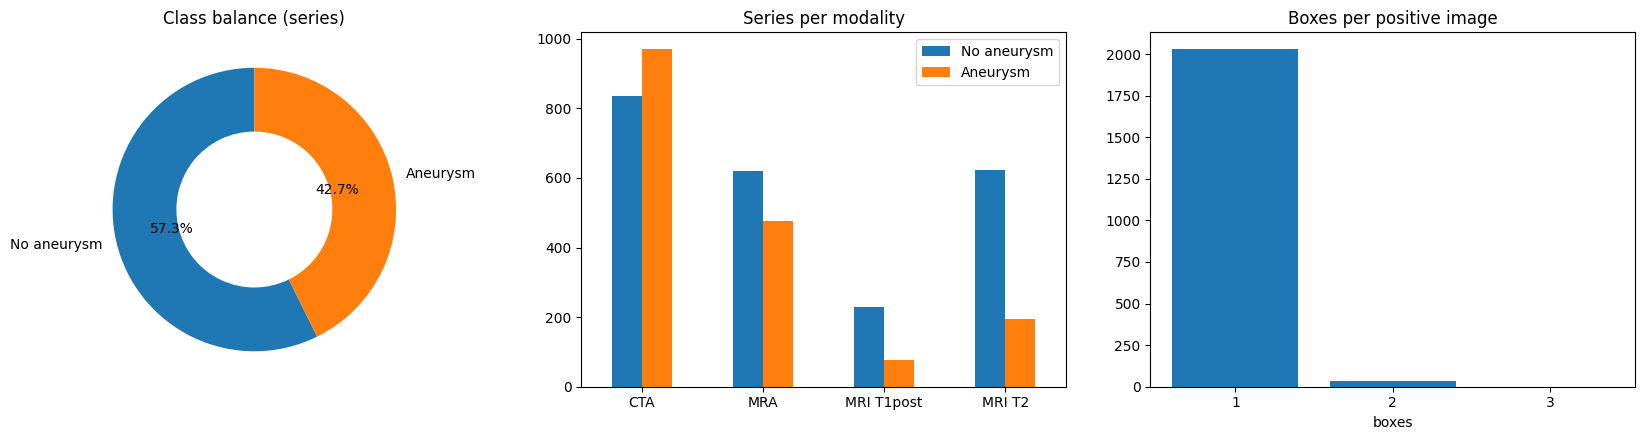

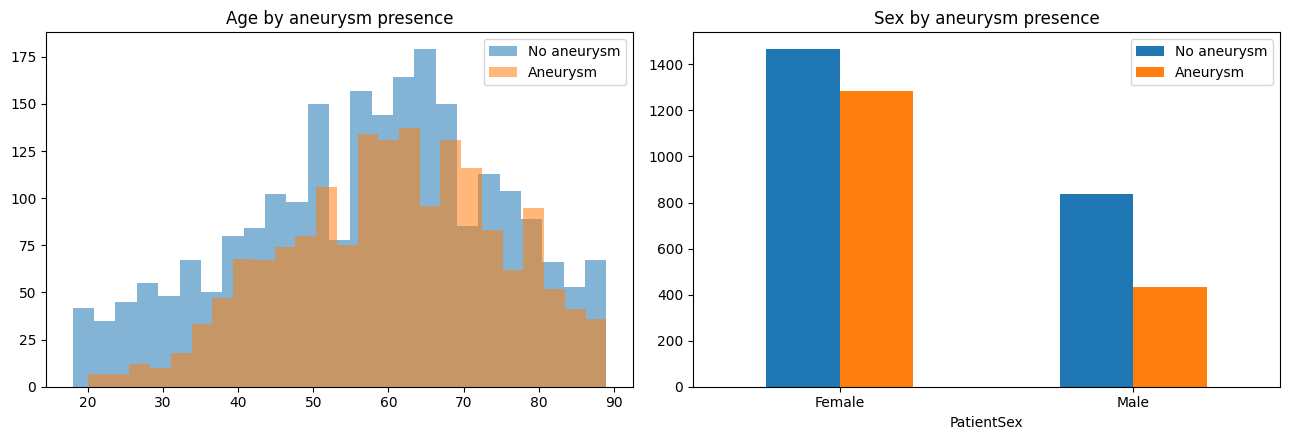

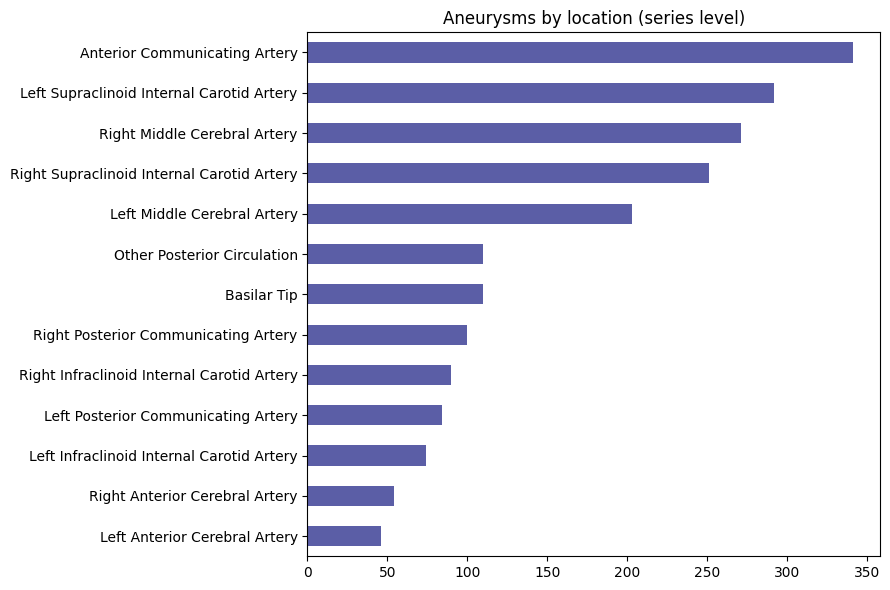

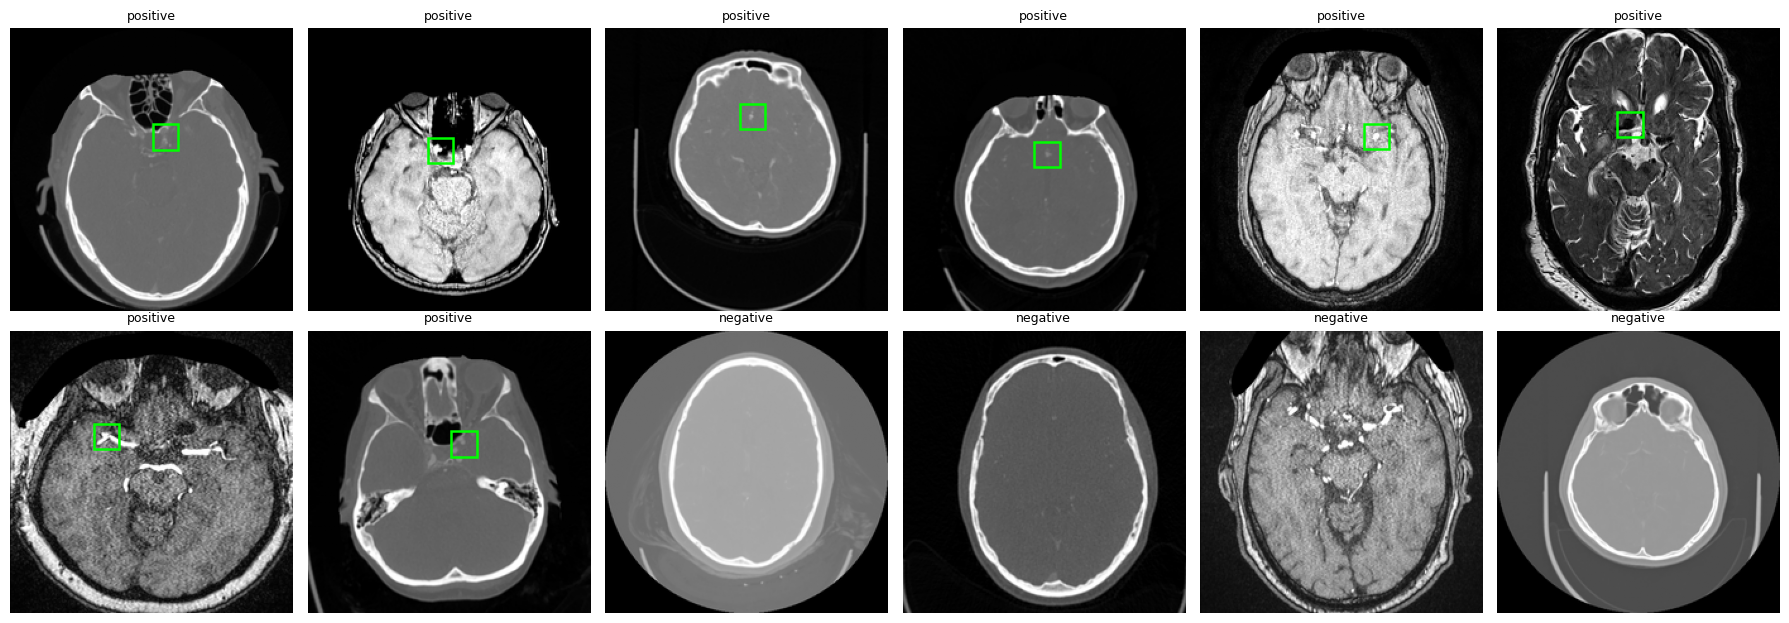

In [9]:
series_level = final_df_v2.drop_duplicates("SeriesInstanceUID").copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
counts = series_level["Aneurysm Present"].value_counts().sort_index()
axes[0].pie(counts, labels=["No aneurysm", "Aneurysm"], autopct="%1.1f%%", startangle=90, wedgeprops=dict(width=0.45))
axes[0].set_title("Class balance (series)")
ct = pd.crosstab(series_level["Modality"], series_level["Aneurysm Present"])
ct.columns = ["No aneurysm", "Aneurysm"]
ct.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Series per modality")
axes[1].set_xlabel("")
bpi = final_df_v2[final_df_v2["Aneurysm Present"] == 1].groupby("image_path").size().value_counts().sort_index()
axes[2].bar(bpi.index.astype(str), bpi.values)
axes[2].set_title("Boxes per positive image")
axes[2].set_xlabel("boxes")
plt.tight_layout()
plt.savefig(f"{OUT}/fig_dataset_overview.png", dpi=150)
plt.show()

if {"PatientAge", "PatientSex"}.issubset(series_level.columns):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for v, g in series_level.groupby("Aneurysm Present"):
        axes[0].hist(g["PatientAge"].dropna(), bins=25, alpha=0.55, label=["No aneurysm", "Aneurysm"][int(v)])
    axes[0].set_title("Age by aneurysm presence")
    axes[0].legend()
    pd.crosstab(series_level["PatientSex"], series_level["Aneurysm Present"]).plot(kind="bar", ax=axes[1], rot=0)
    axes[1].set_title("Sex by aneurysm presence")
    axes[1].legend(["No aneurysm", "Aneurysm"])
    plt.tight_layout()
    plt.savefig(f"{OUT}/fig_age_sex.png", dpi=150)
    plt.show()

location_cols = [c for c in [
    "Left Infraclinoid Internal Carotid Artery", "Right Infraclinoid Internal Carotid Artery",
    "Left Supraclinoid Internal Carotid Artery", "Right Supraclinoid Internal Carotid Artery",
    "Left Middle Cerebral Artery", "Right Middle Cerebral Artery", "Anterior Communicating Artery",
    "Left Anterior Cerebral Artery", "Right Anterior Cerebral Artery",
    "Left Posterior Communicating Artery", "Right Posterior Communicating Artery",
    "Basilar Tip", "Other Posterior Circulation"] if c in series_level.columns]
if location_cols:
    loc_counts = series_level[location_cols].sum().sort_values()
    fig, ax = plt.subplots(figsize=(9, 6))
    loc_counts.plot(kind="barh", ax=ax, color="#5B5EA6")
    ax.set_title("Aneurysms by location (series level)")
    plt.tight_layout()
    plt.savefig(f"{OUT}/fig_location.png", dpi=150)
    plt.show()

# sanity figure: boxes must sit on the structure they annotate
pos_imgs = final_df_v2[final_df_v2["Aneurysm Present"] == 1].groupby("image_path")
neg_imgs = final_df_v2[final_df_v2["Aneurysm Present"] == 0].drop_duplicates("image_path")
sample_pos = random.Random(1).sample(list(pos_imgs.groups.keys()), 8)
sample_neg = neg_imgs.sample(4, random_state=1)["image_path"].tolist()
fig, axes = plt.subplots(2, 6, figsize=(18, 6.3))
for ax, p in zip(axes.flatten(), sample_pos + sample_neg):
    img = cv2.imread(f"{OUT}/{p}", cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    if p in pos_imgs.groups:
        for _, r in pos_imgs.get_group(p).iterrows():
            ax.add_patch(plt.Rectangle(((r.x_center - r.box_w / 2) * IMG_SIZE, (r.y_center - r.box_h / 2) * IMG_SIZE),
                                       r.box_w * IMG_SIZE, r.box_h * IMG_SIZE, fill=False, edgecolor="lime", lw=1.8))
        ax.set_title("positive", fontsize=9)
    else:
        ax.set_title("negative", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT}/fig_sample_images.png", dpi=150)
plt.show()

## Step 10: Write manifest and list outputs

In [10]:
manifest = dict(
    seed=SEED, box_size_px=BOX_SIZE, image_size=IMG_SIZE,
    n_series=int(final_df_v2["SeriesInstanceUID"].nunique()),
    n_images=int(final_df_v2["image_path"].nunique()),
    n_boxes=int(final_df_v2["x_center"].notna().sum()),
    multiframe_positive_series_excluded=len(excluded_series),
    negative_series_skipped=neg_skipped,
    shortcut_auc_all=float(shortcut_df.loc[0, "pixel_stats_auc"]),
)
json.dump(manifest, open(f"{OUT}/data_manifest.json", "w"), indent=2)
print(json.dumps(manifest, indent=2))
total = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(OUT) for f in fs)
print(f"Output size: {total / 1e9:.2f} GB")
print(sorted(f for f in os.listdir(OUT) if not f.startswith(".")))

{
  "seed": 42,
  "box_size_px": 20,
  "image_size": 224,
  "n_series": 4023,
  "n_images": 4372,
  "n_boxes": 2106,
  "multiframe_positive_series_excluded": 142,
  "negative_series_skipped": {
    "multiframe": 180,
    "missing": 0,
    "error": 0
  },
  "shortcut_auc_all": 0.644
}
Output size: 0.12 GB
['__notebook__.ipynb', 'data_manifest.json', 'fig_age_sex.png', 'fig_dataset_overview.png', 'fig_location.png', 'fig_sample_images.png', 'final_df_v2.csv', 'shortcut_check.csv', 'split_70_15_15.csv', 'split_80_10_10.csv', 'split_85_7dot5_7dot5.csv', 'split_summary.csv', 'v2_png']
